# Simple Multimodal Test - Variational Inference

Compare 3 models to assess performance:

1. Trained only one one modality
2. Trained jointly on all modalities as vector output
3. One main model with separate models for other modalities as additional input

**Fit using Variational Inference**, with the custom guide defined in this package.

In [22]:
import logging
import numpy as np
import scipy.stats as stats
import torch
import itertools
import matplotlib.pyplot as plt
import pyro
from pyro.infer import NUTS, MCMC, Predictive
import pyro.infer.autoguide as autoguide
from pyro.infer.autoguide import init_to_sample
import pyro.distributions as dist
from pyro.contrib.autoname import scope
import pyro.poutine as poutine
import math
import statistics

import mmbo.examples.testfunc as testfunc
from mmbo.nn import TIBNN, LayeredTIBNN, TIBNNGuide


In [58]:
# Consistent network parameters
width = 1000
depth = 1
output_bias = True
bias_ordering = False
bias_positive = False
#residual_prior = dist.Exponential(5)
#residual_prior = dist.LogNormal(np.log(0.1), np.log(np.sqrt(10)))
#residual_prior = dist.HalfCauchy(1)
residual_prior = dist.Uniform(0, 0.5)

# Consistent sampling parameters
warmup_steps = 150
num_samples = 50
num_chains = 2

In [33]:
def plot_predictions(model, guide, x_plot, y_plot, x_train, y_train, pred_site="mu", num_samples = 100):
    # Set up figure/axes
    fig, ax = plt.subplots(figsize=(10, 5))
    xlims = [1.05*x_plot.min() - 0.05*x_plot.max(), 1.05*x_plot.max() - 0.05*x_plot.min()]
    ylims = [1.5*y_plot.min() - 0.5*y_plot.max(), 1.5*y_plot.max() - 0.5*y_plot.min()]
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=30)
    plt.ylabel("Y", fontsize=30)
    # Plot predicted means
    preds = Predictive(model, guide = guide, return_sites=[pred_site], num_samples=num_samples)(x_plot)
    for inst in range(preds[pred_site].shape[0]):
        y_inst = preds[pred_site][inst,:,-1]
        ax.plot(x_plot.squeeze(), y_inst, '-', linewidth=0.5, alpha=0.2, color="red", zorder = 0)
    # Plot confidence bands
    y_pred_mean = preds[pred_site].mean(0)[:,-1]
    y_pred_std = preds[pred_site].std(0)[:,-1]
    ax.plot(x_plot.squeeze(), y_pred_mean, '-', linewidth=3, color="#408765", label="predictive mean", zorder = 10)
    ax.fill_between(x_plot.squeeze(), y_pred_mean - 2 * y_pred_std, y_pred_mean + 2 * y_pred_std, alpha=0.6, color='#86cfac', zorder=5)
    # Plot true function
    ax.plot(x_plot.squeeze(), y_plot.squeeze(), 'b-', linewidth=3, label="true function", zorder = 15)
    # Plot data points
    ax.plot(x_train.squeeze(), y_train.squeeze(), 'ko', markersize=4, label="observations", zorder = 20)
    plt.legend(loc="lower right")

## Generate test data

In [4]:
def _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full, shuffle):
    rng = np.random.default_rng(seed)
    ntrain = ntrainpergroup * (2 ** len(modes) - 1)
    # Training Data
    X_train = np.linspace(xmin, xmax, num=ntrain)
    if shuffle:
        rng.shuffle(X_train)
    Y_train = np.empty((ntrain, len(modes)))
    Y_train.fill(np.nan)
    combinations = list(itertools.chain.from_iterable([itertools.combinations(range(len(modes)), r) for r in range(1,len(modes)+1)])) * ntrainpergroup
    for r in range(ntrain):
        for c in combinations[r]:
            Y_train[r,c] = func(X_train[r], modes[c])
    Y_train_full = np.zeros((ntrain, len(modes)))
    for i,m in enumerate(modes):
        Y_train_full[:,i] = func(X_train, m)
    # Package and return
    X_train_pt = torch.Tensor(np.float32(X_train.reshape((ntrain,1))))
    Y_train_pt = torch.Tensor(np.float32(Y_train))
    Y_train_full_pt = torch.Tensor(np.float32(Y_train_full))
    if full:
        return X_train_pt, Y_train_pt, Y_train_full_pt
    else:
        return X_train_pt, Y_train_pt

def _molecule_train_data(func, xmin, xmax, ntrainpergroup, seed, full, shuffle):
    modes = func.modes
    return _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full, shuffle)

def li2_train_data(ntrainpergroup, seed=None, full=False, shuffle=True):
    return _molecule_train_data(testfunc.li2_energy, 0.5, 11.0, ntrainpergroup, seed, full, shuffle)

def be2_train_data(ntrainpergroup, seed=None, full=False, shuffle=True):
    return _molecule_train_data(testfunc.be2_energy, 0.5, 5.0, ntrainpergroup, seed, full, shuffle)

def nice_periodic_train_data(ntrainpergroup, nummodes=5, seed=None, full=False, shuffle=True):
    return _train_data(testfunc.nice_periodic, list(range(nummodes)), -np.pi, np.pi, ntrainpergroup, seed, full, shuffle)

Text(0.5, 1.0, 'Training Data')

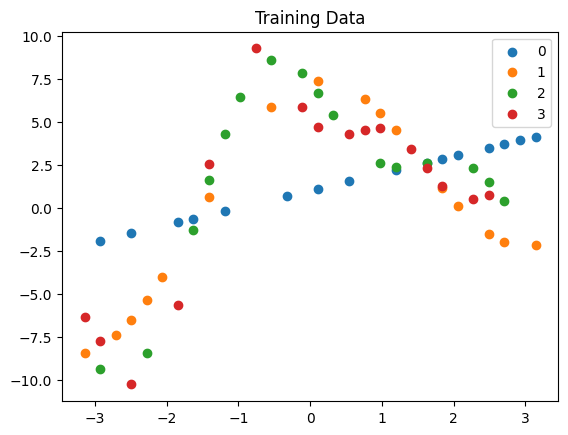

In [5]:
n_modes = 4

X_train, Y_train, Y_train_full = nice_periodic_train_data(2, n_modes, 1234, full=True)

X_plot, _, Y_plot = nice_periodic_train_data(100, n_modes, 1234, full=True, shuffle=False)

for i,m in enumerate(range(n_modes)):
    plt.scatter(X_train.detach(), Y_train.detach()[:,i], label=m)
plt.legend(loc="upper right")
plt.title("Training Data")

In [6]:
pyro.set_rng_seed(2024)

In [37]:
def do_svi(svi, *args, check_interval=1000, max_nonimproved = 3, **kwargs):
    losses = []
    current_loss = 0
    nonimproved = 0
    while nonimproved < max_nonimproved:
        loss = svi.step(*args, **kwargs)
        losses.append(loss)
        if len(losses) >= 2 * check_interval and len(losses) % check_interval == 0:
            current_loss = statistics.mean(losses[-check_interval:])
            reg = stats.linregress(range(2*check_interval), losses[-2*check_interval:], alternative = "less")
            if reg.pvalue > 0.1:
                nonimproved += 1
            else:
                nonimproved = 0
            logging.info("Step {} Average Elbo loss: {:.1f} (slope = {:.3f} loss/iter, p-value = {:.3f}) {}".format(len(losses), current_loss, reg.slope, reg.pvalue, '*'*nonimproved))
    return losses

## 1. Single Modality Model

Step 1000 Average Elbo loss: 140871.3 (slope = -413.135 loss/iter, p-value: 0.000) 
Step 1500 Average Elbo loss: 50206.2 (slope = -186.995 loss/iter, p-value: 0.000) 
Step 2000 Average Elbo loss: 31171.6 (slope = -36.441 loss/iter, p-value: 0.000) 
Step 2500 Average Elbo loss: 22569.1 (slope = -16.625 loss/iter, p-value: 0.000) 
Step 3000 Average Elbo loss: 18781.4 (slope = -7.660 loss/iter, p-value: 0.000) 
Step 3500 Average Elbo loss: 17315.7 (slope = -2.784 loss/iter, p-value: 0.000) 
Step 4000 Average Elbo loss: 16299.2 (slope = -1.918 loss/iter, p-value: 0.000) 
Step 4500 Average Elbo loss: 15899.0 (slope = -0.644 loss/iter, p-value: 0.104) *
Step 5000 Average Elbo loss: 14895.7 (slope = -1.462 loss/iter, p-value: 0.002) 
Step 5500 Average Elbo loss: 13848.5 (slope = -1.898 loss/iter, p-value: 0.000) 
Step 6000 Average Elbo loss: 13244.7 (slope = -1.368 loss/iter, p-value: 0.000) 
Step 6500 Average Elbo loss: 11842.9 (slope = -2.474 loss/iter, p-value: 0.000) 
Step 7000 Average El

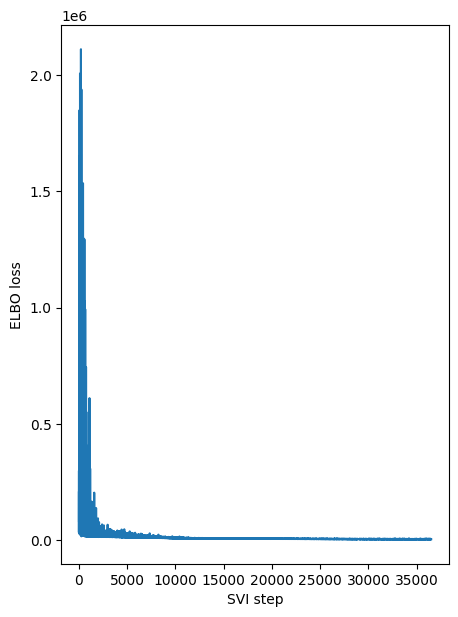

In [60]:
single = TIBNN.from_data(X_train, Y_train[:,-1:], width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

#single_guide = TIBNNGuide(single)
last_layer = ['chain.2.bias', 'chain.2.weight']
scales = ['chain.1.scale',]
single_guide = autoguide.AutoGuideList(single)
single_guide.append(autoguide.AutoMultivariateNormal(poutine.block(single, expose=last_layer)))
single_guide.append(autoguide.AutoDelta(poutine.block(single, expose=scales)))
single_guide.append(autoguide.AutoDiagonalNormal(poutine.block(single, hide=scales + last_layer)))

logging.basicConfig(format='%(message)s', level=logging.INFO)

pyro.clear_param_store()

#auto_guide = model.guide()
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
single_svi = pyro.infer.SVI(single, single_guide, adam, elbo)

losses = do_svi(single_svi, X_train, Y_train, check_interval = 500, max_nonimproved = 3)

plt.figure(figsize=(5, 7))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

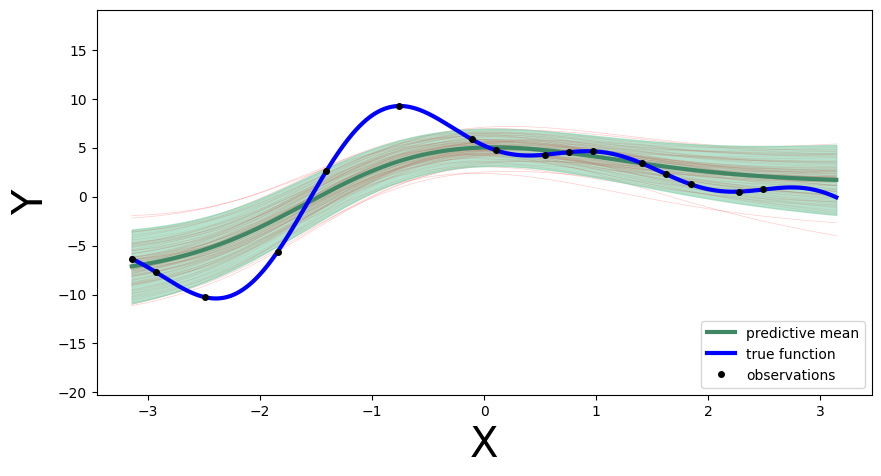

In [61]:
plot_predictions(single, single_guide, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:])

tensor(19594)

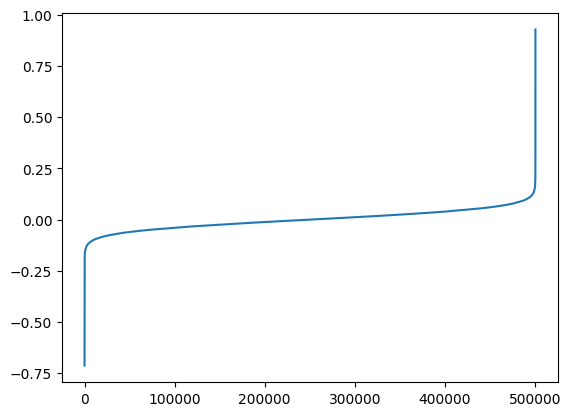

In [99]:
scale_tril = pyro.get_param_store()['AutoGuideList.0.scale_tril']
scale = pyro.get_param_store()['AutoGuideList.0.scale']
cov = (scale * scale_tril) @ (scale * scale_tril).mT
tocorr = torch.diag(cov.diagonal()).inverse().sqrt()
cor = (tocorr @ cov @ tocorr)
plt.plot(cor[(cor.abs().tril(-1) > 0)].sort().values.detach())
(cor.abs().tril(-1) > 0.1).sum()


## 2. Joint output Model

In [ ]:
multiple = TIBNN.from_data(X_train, Y_train, width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

last_layer = ['chain.4.bias', 'chain.4.weight']
multiple_guide = autoguide.AutoGuideList(multiple)
multiple_guide.append(autoguide.AutoMultivariateNormal(poutine.block(multiple, expose=last_layer)))
multiple_guide.append(autoguide.AutoDelta(poutine.block(multiple, hide=last_layer)))


logging.basicConfig(format='%(message)s', level=logging.INFO)

pyro.clear_param_store()

#auto_guide = model.guide()
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 2)
multiple_svi = pyro.infer.SVI(multiple, multiple_guide, adam, elbo)

losses = do_svi(multiple_svi, X_train, Y_train, check_interval = 500)

plt.figure(figsize=(5, 7))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

In [ ]:
plot_predictions(multiple, multiple_guide, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:])

In [ ]:
Predictive(multiple, guide = multiple_guide, num_samples = 100)(X_plot)['sigma']

## 3. Separate Model with Predictors

In [ ]:
layered = LayeredTIBNN.from_data(X_train, Y_train[:,:-1], Y_train[:,-1:], width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

layered_guide = pyro.infer.autoguide.AutoNormal(layered)

logging.basicConfig(format='%(message)s', level=logging.INFO)

pyro.clear_param_store()

#auto_guide = model.guide()
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 2)
layered_svi = pyro.infer.SVI(layered, layered_guide, adam, elbo)

losses = do_svi(layered_svi, X_train, Y_train[:,:-1], Y_train[:,-1:], check_interval = 500)

plt.figure(figsize=(5, 7))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

In [ ]:
plot_predictions(layered, layered_guide, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:], pred_site="second/mu")